# MLP (deep learning) classifier: binary and multiclass

Uses the files from the preprocessing notebook (`processed/`). Trains two Keras MLPs:
1. **Binary** (`label`): normal vs attack.
2. **Multiclass**: the classes defined by `CLASS_SCHEME` in the preprocessing notebook.

## 1. Imports

In [1]:
import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

model = keras.Sequential([
    keras.layers.Dense(10, activation="relu", input_shape=(5,)),
    keras.layers.Dense(1, activation="sigmoid")
])

print("Keras model created successfully!")
model.summary()

TensorFlow version: 2.21.0
Keras version: 3.15.1
Keras model created successfully!


c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71 (284.00 B)

 Trainable params: 71 (284.00 B)

 Non-trainable params: 0 (0.00 B)

In [2]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import keras
from keras import layers
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)

print("keras", keras.__version__)

keras 3.15.1


## 2. Config

In [3]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

HIDDEN_UNITS = (128, 64, 32)   # three hidden layers
DROPOUT = 0.3
LEARNING_RATE = 1e-3
BATCH_SIZE = 512
EPOCHS = 60                    # early stopping usually ends training much sooner
PATIENCE = 8                   # stop after this many epochs without validation improvement

keras.utils.set_random_seed(SEED)

## 3. Load the processed data

In [4]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype("int32"), data["y_bin_val"].astype("int32")
ym_train, ym_val = data["y_multi_train"].astype("int32"), data["y_multi_val"].astype("int32")
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape, "  classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)   classes: ['Normal', 'Reconnaissance', 'Fuzzers', 'Generic', 'Exploit-like']


## 4. Model and training helpers

Each hidden block is Dense, BatchNorm, ReLU, Dropout. Early stopping keeps the weights from the best validation epoch, and the learning rate is halved when validation loss stalls. Class weights from `meta.json` stop the model from ignoring the smaller classes.

In [5]:
def build_mlp(n_in, n_out, binary):
    inputs = keras.Input(shape=(n_in,))
    x = inputs
    for units in HIDDEN_UNITS:
        x = layers.Dense(units, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(DROPOUT)(x)
    if binary:
        outputs = layers.Dense(1, activation="sigmoid")(x)
        loss = "binary_crossentropy"
        metrics = [keras.metrics.AUC(name="auc")]
    else:
        outputs = layers.Dense(n_out, activation="softmax")(x)
        loss = "sparse_categorical_crossentropy"
        metrics = ["accuracy"]
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=loss, metrics=metrics)
    return model


def train(model, X_tr, y_tr, X_va, y_va, class_weight):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight,
                     callbacks=callbacks, verbose=2)
    print(f"trained {len(hist.history['loss'])} epochs in {time.time() - t0:.1f}s")
    return hist


def plot_history(hist, metric, title):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="train")
    axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h[metric], label="train")
    axes[1].plot(h["val_" + metric], label="validation")
    axes[1].set_title(metric.upper()); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## 5. Binary MLP (normal vs attack)

In [6]:
mlp_bin = build_mlp(n_features, 1, binary=True)
mlp_bin.summary()
hist_bin = train(mlp_bin, X_train, yb_train, X_val, yb_val, cw_bin)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 39)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,161 (63.13 KB)

 Trainable params: 15,713 (61.38 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/60
274/274 - 5s - 18ms/step - auc: 0.9475 - loss: 0.2889 - val_auc: 0.9839 - val_loss: 0.1633 - learning_rate: 0.0010
Epoch 2/60
274/274 - 2s - 5ms/step - auc: 0.9746 - loss: 0.2010 - val_auc: 0.9873 - val_loss: 0.1492 - learning_rate: 0.0010
Epoch 3/60
274/274 - 1s - 5ms/step - auc: 0.9791 - loss: 0.1808 - val_auc: 0.9884 - val_loss: 0.1446 - learning_rate: 0.0010
Epoch 4/60
274/274 - 2s - 6ms/step - auc: 0.9814 - loss: 0.1699 - val_auc: 0.9891 - val_loss: 0.1397 - learning_rate: 0.0010
Epoch 5/60
274/274 - 2s - 6ms/step - auc: 0.9828 - loss: 0.1627 - val_auc: 0.9897 - val_loss: 0.1320 - learning_rate: 0.0010
Epoch 6/60
274/274 - 1s - 5ms/step - auc: 0.9836 - loss: 0.1586 - val_auc: 0.9901 - val_loss: 0.1286 - learning_rate: 0.0010
Epoch 7/60
274/274 - 1s - 5ms/step - auc: 0.9842 - loss: 0.1558 - val_auc: 0.9903 - val_loss: 0.1268 - learning_rate: 0.0010
Epoch 8/60
274/274 - 2s - 6ms/step - auc: 0.9846 - loss: 0.1530 - val_auc: 0.9905 - val_loss: 0.1206 - learning_rate: 0.0010

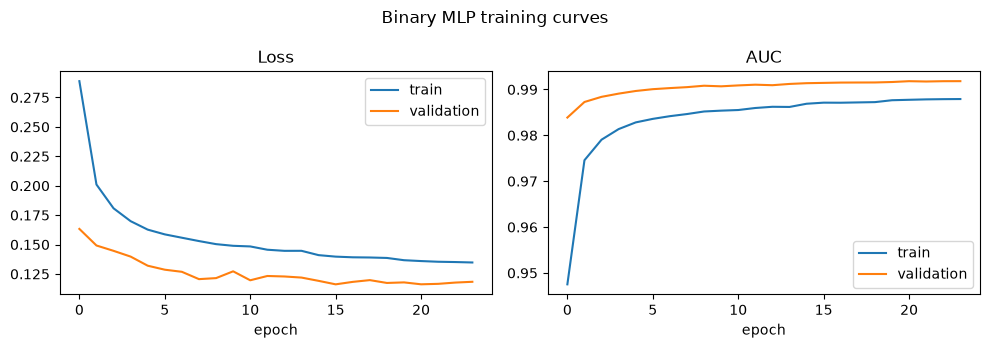

              precision    recall  f1-score   support

      Normal     0.8619    0.9596    0.9082     11200
      Attack     0.9800    0.9279    0.9532     23869

    accuracy                         0.9380     35069
   macro avg     0.9210    0.9437    0.9307     35069
weighted avg     0.9423    0.9380    0.9388     35069

ROC-AUC:              0.9916
False positive rate:  0.0404  (452 normal flows flagged as attacks)
False negative rate:  0.0721  (1722 attacks missed)


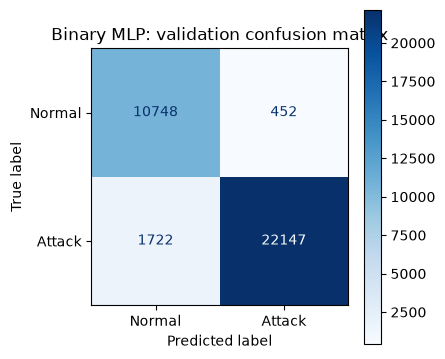

In [7]:
plot_history(hist_bin, "auc", "Binary MLP training curves")

proba_bin = mlp_bin.predict(X_val, batch_size=4096, verbose=0).ravel()
pred_bin = (proba_bin >= 0.5).astype(int)

print(classification_report(yb_val, pred_bin, target_names=["Normal", "Attack"], digits=4))
tn, fp, fn, tp = confusion_matrix(yb_val, pred_bin).ravel()
fpr = fp / (fp + tn)
print(f"ROC-AUC:              {roc_auc_score(yb_val, proba_bin):.4f}")
print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
print(f"False negative rate:  {fn / (fn + tp):.4f}  ({fn} attacks missed)")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    yb_val, pred_bin, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
ax.set_title("Binary MLP: validation confusion matrix")
plt.tight_layout()
plt.show()

### Optional: tune the alert threshold

In [8]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (proba_bin >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(yb_val, p, labels=[0, 1]).ravel()
    rows.append({"threshold": t,
                 "precision": precision_score(yb_val, p, zero_division=0),
                 "recall": recall_score(yb_val, p),
                 "f1": f1_score(yb_val, p),
                 "false_pos_rate": fp_ / (fp_ + tn_)})
pd.DataFrame(rows).round(4)

,threshold,precision,recall,f1,false_pos_rate
0,0.3,0.9523,0.9793,0.9656,0.1046
1,0.4,0.9739,0.9460,0.9597,0.0539
2,0.5,0.9800,0.9279,0.9532,0.0404
3,0.6,0.9879,0.9023,0.9432,0.0235
4,0.7,0.9904,0.8806,0.9323,0.0182
5,0.8,0.9929,0.8596,0.9215,0.0131
6,0.9,0.9968,0.8169,0.8980,0.0055


## 6. Multiclass MLP

In [9]:
mlp_multi = build_mlp(n_features, n_classes, binary=False)
hist_multi = train(mlp_multi, X_train, ym_train, X_val, ym_val, cw_multi)

Epoch 1/60
274/274 - 4s - 16ms/step - accuracy: 0.6945 - loss: 0.8725 - val_accuracy: 0.8214 - val_loss: 0.5585 - learning_rate: 0.0010
Epoch 2/60
274/274 - 1s - 5ms/step - accuracy: 0.7883 - loss: 0.6047 - val_accuracy: 0.8516 - val_loss: 0.4395 - learning_rate: 0.0010
Epoch 3/60
274/274 - 1s - 5ms/step - accuracy: 0.8141 - loss: 0.5349 - val_accuracy: 0.8610 - val_loss: 0.4044 - learning_rate: 0.0010
Epoch 4/60
274/274 - 1s - 5ms/step - accuracy: 0.8292 - loss: 0.4980 - val_accuracy: 0.8710 - val_loss: 0.3795 - learning_rate: 0.0010
Epoch 5/60
274/274 - 1s - 5ms/step - accuracy: 0.8403 - loss: 0.4723 - val_accuracy: 0.8800 - val_loss: 0.3602 - learning_rate: 0.0010
Epoch 6/60
274/274 - 2s - 6ms/step - accuracy: 0.8472 - loss: 0.4550 - val_accuracy: 0.8825 - val_loss: 0.3474 - learning_rate: 0.0010
Epoch 7/60
274/274 - 2s - 6ms/step - accuracy: 0.8523 - loss: 0.4442 - val_accuracy: 0.8861 - val_loss: 0.3378 - learning_rate: 0.0010
Epoch 8/60
274/274 - 1s - 5ms/step - accuracy: 0.8545 

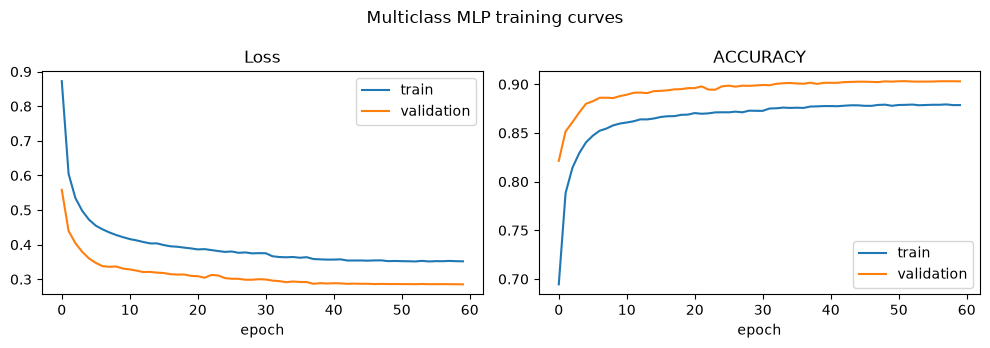

                precision    recall  f1-score   support

        Normal     0.9920    0.8557    0.9188     11200
Reconnaissance     0.7907    0.8118    0.8011      2099
       Fuzzers     0.6354    0.8820    0.7387      3637
       Generic     0.9996    0.9801    0.9898      8000
  Exploit-like     0.9006    0.9208    0.9106     10133

      accuracy                         0.9030     35069
     macro avg     0.8637    0.8901    0.8718     35069
  weighted avg     0.9183    0.9030    0.9069     35069

macro F1:    0.8718
weighted F1: 0.9069


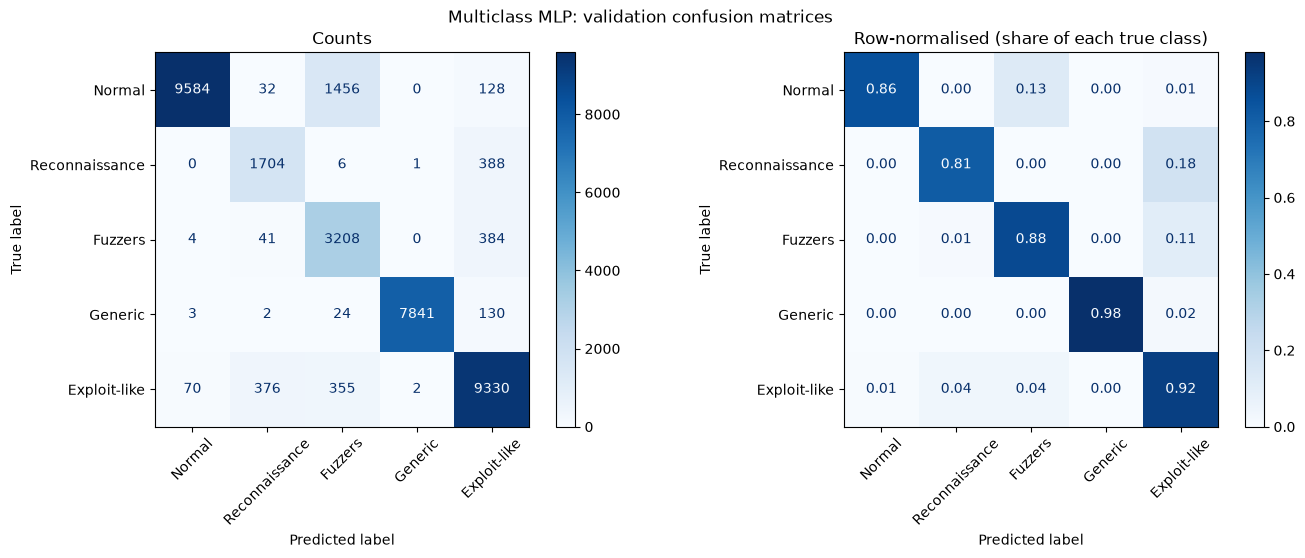

In [10]:
plot_history(hist_multi, "accuracy", "Multiclass MLP training curves")

pred_multi = mlp_multi.predict(X_val, batch_size=4096, verbose=0).argmax(axis=1)
labels = list(range(n_classes))

print(classification_report(ym_val, pred_multi, labels=labels, target_names=class_names,
                            digits=4, zero_division=0))
print("macro F1:    %.4f" % f1_score(ym_val, pred_multi, average="macro"))
print("weighted F1: %.4f" % f1_score(ym_val, pred_multi, average="weighted"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(
    ym_val, pred_multi, labels=labels, display_labels=class_names,
    cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(
    ym_val, pred_multi, labels=labels, display_labels=class_names,
    normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
axes[1].set_title("Row-normalised (share of each true class)")
plt.suptitle("Multiclass MLP: validation confusion matrices")
plt.tight_layout()
plt.show()

## 7. Detection rate by attack type

Was the flow flagged as an attack at all, and was it given the right type? For the Normal row, the first column is the false alarm rate.

In [11]:
flagged = pred_multi != 0          # class 0 is Normal
rows = []
for i, name in enumerate(class_names):
    m = ym_val == i
    rows.append({"true class": name, "flows": int(m.sum()),
                 "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                 "correct type (%)": round(100 * (pred_multi[m] == i).mean(), 2)})
pd.DataFrame(rows)

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,14.43,85.57
1,Reconnaissance,2099,100.00,81.18
2,Fuzzers,3637,99.89,88.20
3,Generic,8000,99.96,98.01
4,Exploit-like,10133,99.31,92.08


## 8. Compare with the Random Forest

Loads the Random Forest summary saved by the other notebook, if it exists.

In [12]:
mlp_summary = pd.DataFrame([
    {"model": "MLP binary",
     "precision": precision_score(yb_val, pred_bin),
     "recall": recall_score(yb_val, pred_bin),
     "f1": f1_score(yb_val, pred_bin),
     "false_pos_rate": fpr},
    {"model": "MLP multiclass (macro)",
     "precision": precision_score(ym_val, pred_multi, average="macro", zero_division=0),
     "recall": recall_score(ym_val, pred_multi, average="macro", zero_division=0),
     "f1": f1_score(ym_val, pred_multi, average="macro"),
     "false_pos_rate": np.nan},
])

rf_path = Path(MODEL_DIR) / "rf_validation_summary.csv"
if rf_path.exists():
    comparison = pd.concat([pd.read_csv(rf_path), mlp_summary], ignore_index=True)
else:
    print("rf_validation_summary.csv not found: run the Random Forest notebook to enable the comparison.")
    comparison = mlp_summary
comparison.round(4)

,model,precision,recall,f1,false_pos_rate
0,RF binary,0.9757,0.9610,0.9683,0.0511
1,RF multiclass (macro),0.8420,0.8675,0.8528,NaN
2,MLP binary,0.9800,0.9279,0.9532,0.0404
3,MLP multiclass (macro),0.8637,0.8901,0.8718,NaN


## 9. Save the models

Keras models are saved in the `.keras` format. The binary model is what the FastAPI backend will load first.

In [13]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

mlp_bin.save(mdir / "mlp_binary.keras")
mlp_multi.save(mdir / "mlp_multiclass.keras")
mlp_summary.to_csv(mdir / "mlp_validation_summary.csv", index=False)
(mdir / "mlp_history.json").write_text(json.dumps({
    "binary": {k: [float(v) for v in vals] for k, vals in hist_bin.history.items()},
    "multiclass": {k: [float(v) for v in vals] for k, vals in hist_multi.history.items()},
}))

for f in sorted(mdir.glob("mlp_*")):
    print(f"{f.name:30s} {f.stat().st_size / 1e3:9.1f} KB")

mlp_binary.keras                   254.4 KB
mlp_history.json                     8.9 KB
mlp_multiclass.keras               255.7 KB
mlp_validation_summary.csv           0.2 KB


## 10. Using the saved model later (live pipeline)

```python
model = keras.models.load_model("models/mlp_binary.keras")
X = transform_with_artifacts(build_model_frame(flows_df))   # from the preprocessing notebook
alert = model.predict(X, verbose=0).ravel() >= 0.5
```